# Single-stock risk report
Prabhutosh Kumar · adjusted-price analysis · daily log returns

In [1]:
# Parameters
ticker = "AAPL"
start_date = "2024-01-01"
end_date = "2024-12-31"
db_path = "data/data.db"

In [2]:
# Parameters
ticker = "MSFT"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "/Users/prabhu/PythonProjects/UCB-MFE-python-preprogram-2026-winter/Homeworks/HW2/Prabhutosh_Kumar/data/data.db"


In [3]:
%matplotlib inline
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from analysis import (load_stock, calculate_returns, calculate_volatility,
                      calculate_max_drawdown, calculate_sharpe_ratio, metrics, plot_report)
frame = load_stock(db_path, ticker, start_date, end_date)
print(f"{ticker} from {start_date} to {end_date}: {len(frame)} trading days")
print(f"Actual observations: {frame.index.min().date()} to {frame.index.max().date()}")
display(frame.head())
display(frame.tail())
if len(frame) < 21:
    print("Insufficient history for 20 returns: rolling volatility is unavailable.")
if len(frame) < 50:
    print("Insufficient history for a 50-day moving average.")
print("Missing sessions are not filled. Returns span consecutive retained observations; gaps can affect daily-risk estimates.")

MSFT from 2024-06-01 to 2024-11-30: 97 trading days
Actual observations: 2024-06-03 to 2024-10-18


,open,high,low,close,adj_close,volume,ticker,original_ticker,source_row,repair_flags,extreme_return_review,adjustment_factor
ts,,,,,,,,,,,,
2024-06-03,415.53,416.43,408.92,413.52,412.78,17484675,MSFT,MSFT,290813,,0,0.998210
2024-06-04,412.43,416.44,409.68,416.07,415.32,14348917,MSFT,MSFT,290814,,0,0.998197
2024-06-05,417.81,424.08,416.30,424.01,423.25,16988038,MSFT,MSFT,290815,,0,0.998208
2024-06-06,424.01,425.31,420.58,424.52,423.76,14861251,MSFT,MSFT,290817,,0,0.998210
2024-06-07,426.20,426.28,423.00,423.85,423.09,13621650,MSFT,MSFT,290818,,0,0.998207


,open,high,low,close,adj_close,volume,ticker,original_ticker,source_row,repair_flags,extreme_return_review,adjustment_factor
ts,,,,,,,,,,,,
2024-10-14,417.77,424.04,417.52,419.14,419.14,16653100,MSFT,MSFT,290913,,0,1.0
2024-10-15,422.18,422.48,415.26,418.74,418.74,18900201,MSFT,MSFT,290914,,0,1.0
2024-10-16,415.17,416.36,410.48,416.12,416.12,15508932,MSFT,MSFT,290915,,0,1.0
2024-10-17,422.36,422.50,415.59,416.72,416.72,14820004,MSFT,MSFT,290916,adj_close_from_reference_date_factor,0,1.0
2024-10-18,417.14,419.65,416.26,418.16,418.16,15820564,MSFT,MSFT,290917,,0,1.0


Missing sessions are not filled. Returns span consecutive retained observations; gaps can affect daily-risk estimates.


## Risk measures
All report returns use adjusted close. Rolling volatility uses 20 log returns and sample standard deviation, annualized by √252. Warm-up gaps are preserved. Sharpe uses the course approximation `(mean log return × 252 − 0.02)/(sample std × √252)`; undefined or zero volatility displays N/A. Drawdown can recover; its minimum is maximum drawdown.

Price segments use mean rolling volatility as a retrospective threshold (red above, green at/below, gray unavailable). Comparisons across stocks with different actual histories are descriptive, not like-for-like performance rankings.

,adj_close,log_return,rolling_volatility,drawdown
ts,,,,
2024-10-14,419.14,0.006751,0.157876,-0.101945
2024-10-15,418.74,-0.000955,0.153223,-0.102803
2024-10-16,416.12,-0.006277,0.151159,-0.108416
2024-10-17,416.72,0.001441,0.132539,-0.107131
2024-10-18,418.16,0.003450,0.132650,-0.104045


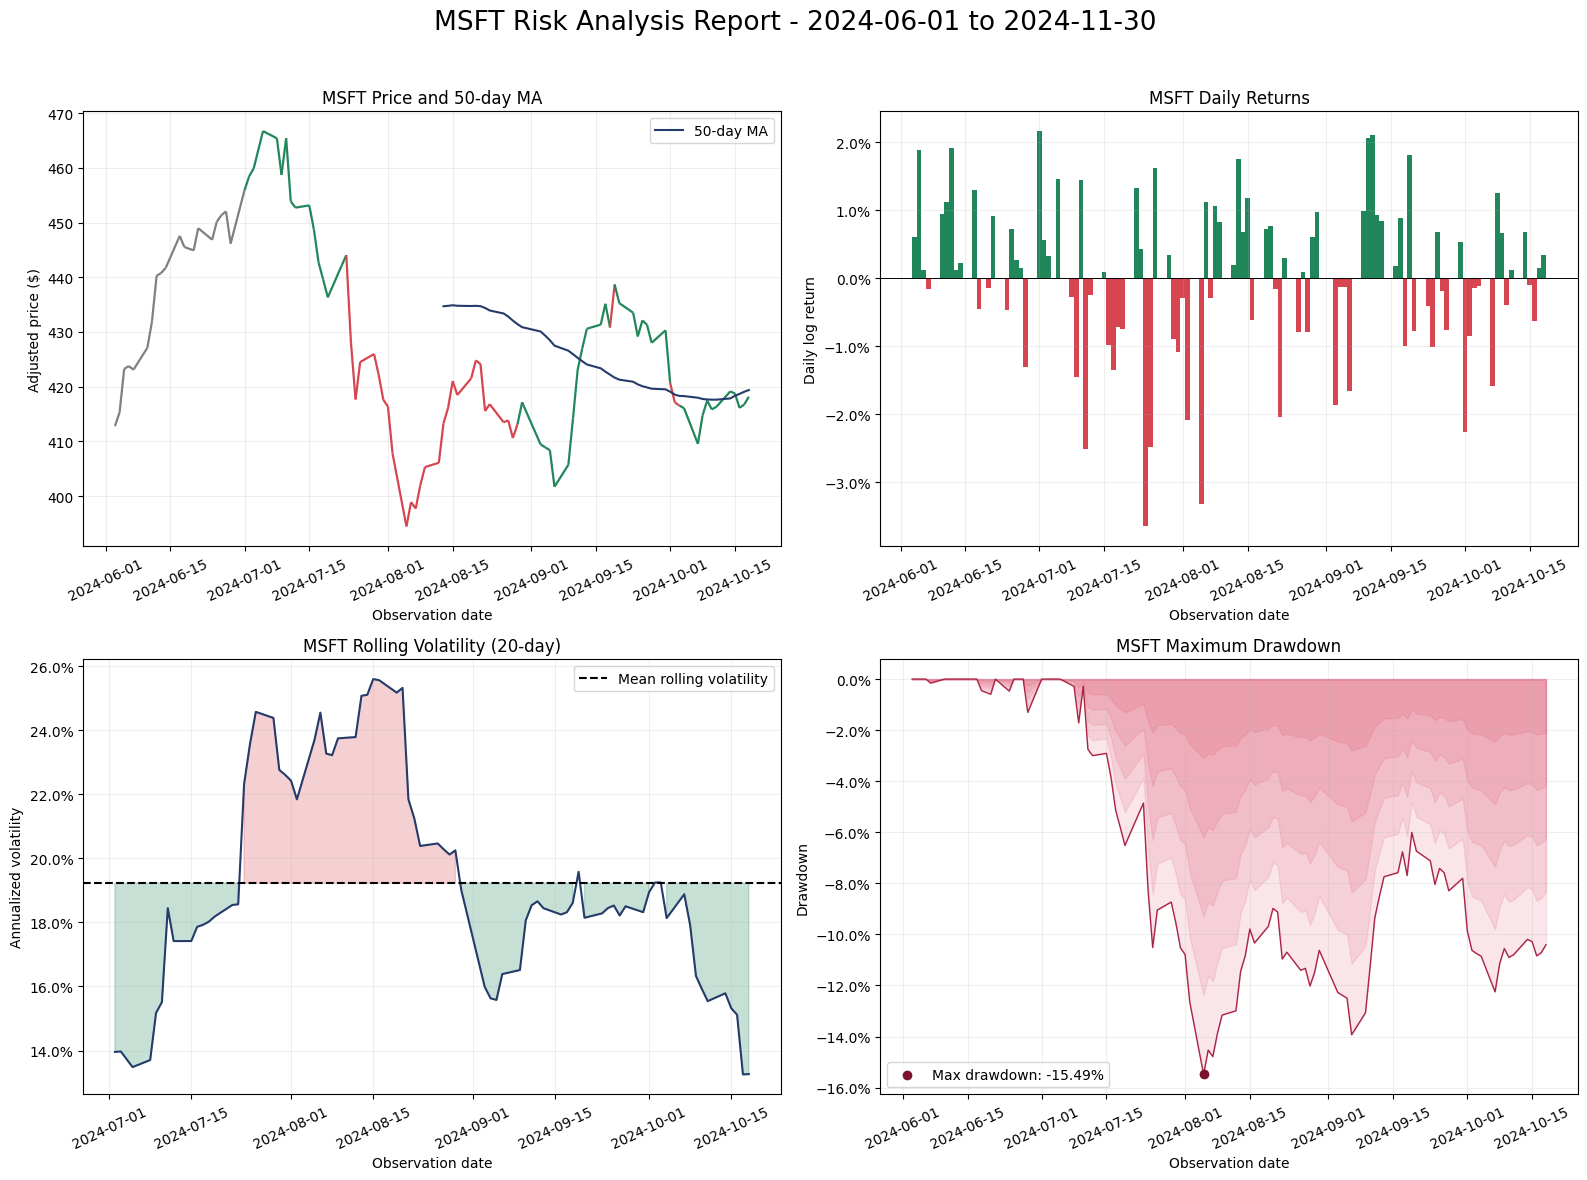

In [4]:
frame["log_return"] = calculate_returns(frame.adj_close)
frame["rolling_volatility"] = calculate_volatility(frame.log_return)
frame["drawdown"] = calculate_max_drawdown(frame.adj_close)
summary = metrics(frame)
display(frame[["adj_close", "log_return", "rolling_volatility", "drawdown"]].tail())
figure = plot_report(frame, ticker, start_date, end_date)
plt.show()
plt.close(figure)

## Summary
Total return is the endpoint price ratio minus one. Annualized return compounds log returns using 252/n. Whole-period annualized volatility differs from the mean rolling volatility used in the portfolio scatter. Best/worst days and up/down averages are log returns. Positive days include zero-return days in the denominator; empty subsets show N/A.

In [5]:
labels = {"total_return": "Total Return", "annualized_return": "Annualized Return",
          "annualized_volatility": "Annualized Volatility", "sharpe_ratio": "Sharpe Ratio",
          "max_drawdown": "Maximum Drawdown", "best_day": "Best Day", "worst_day": "Worst Day",
          "positive_days": "Positive Days", "average_up_day": "Average Up Day", "average_down_day": "Average Down Day"}
rows = []
for key, label in labels.items():
    value = summary[key]
    formatted = "N/A" if not np.isfinite(value) else (f"{value:.2f}" if key == "sharpe_ratio" else f"{value:+.2%}")
    rows.append({"Metric": label, "Value": formatted})
display(pd.DataFrame(rows).set_index("Metric"))

,Value
Metric,
Total Return,+1.30%
Annualized Return,+3.46%
Annualized Volatility,+18.74%
Sharpe Ratio,0.07
Maximum Drawdown,-15.49%
Best Day,+2.16%
Worst Day,-3.65%
Positive Days,+54.17%
Average Up Day,+0.86%


In [6]:
# Named machine-readable result collected only after successful execution.
output = {key: (float(value) if np.isfinite(value) else None) for key, value in summary.items()}
output.update(ticker=ticker, actual_start=str(frame.index.min().date()),
              actual_end=str(frame.index.max().date()), observations=len(frame))
print("HW2_SUMMARY=" + json.dumps(output, allow_nan=False))

HW2_SUMMARY={"total_return": 0.0130335772081982, "annualized_return": 0.03457643244176318, "annualized_volatility": 0.1873625885334212, "sharpe_ratio": 0.0746792571881531, "max_drawdown": -0.1548680150839905, "best_day": 0.0216402032674632, "worst_day": -0.036510280924103654, "positive_days": 0.5416666666666666, "average_up_day": 0.008574882458941628, "average_down_day": -0.009839648110034694, "avg_daily_return": 0.00013488928149414867, "avg_volatility": 0.19223550253806554, "ticker": "MSFT", "actual_start": "2024-06-03", "actual_end": "2024-10-18", "observations": 97}
